# Khuyến nghị cây trồng bằng K-Nearest Neighbors
**Môn Học máy — notebook thực hành.**

Lần chạy hiện tại đã có output phần đọc dữ liệu, chia tập, EDA và kiểm tra chất lượng dữ liệu phục vụ Bài kiểm tra 1. Các ô mô hình phía sau chưa chạy. Phần nhận xét dưới đây dựa trên output đã lưu của lần chạy này.

Thực hiện từng ô bằng **Shift+Enter**, đọc kết quả rồi mới tiếp tục. Khi chỉ chuẩn bị Bài kiểm tra 1, dừng tại mục “Điểm dừng của Bài kiểm tra 1”; không chọn Run All.

Mục tiêu toàn dự án: tìm hiểu KNN, khảo sát K/metric/weights/scaler, so sánh với Gaussian Naive Bayes, Decision Tree và Random Forest, đánh giá Accuracy/F1 macro và minh họa top-3.

Quy trình: kiểm tra dữ liệu → tách test 20% → EDA trên train → CV phân tầng trên train → chọn cấu hình → đánh giá test → lưu mô hình → demo.
KNN không có epoch: `fit` lưu dữ liệu và có thể xây chỉ mục; `predict` tìm láng giềng rồi bỏ phiếu.


## 1. Lý thuyết cần giải thích được
Với hai mẫu có $d=7$ đặc trưng:

- Euclidean: $D_2(x,z)=\sqrt{\sum_{j=1}^d(x_j-z_j)^2}$.
- Manhattan: $D_1(x,z)=\sum_{j=1}^d|x_j-z_j|$.
- Minkowski: $D_p(x,z)=(\sum_{j=1}^d|x_j-z_j|^p)^{1/p}$, dùng $p\geq1$.
  Manhattan và Euclidean chính là $p=1$ và $p=2$; khảo sát thêm $p=3$ để có trường hợp khác.

KNN tìm `n_neighbors` mẫu gần nhất rồi phân lớp bằng bỏ phiếu:

- `uniform`: mỗi láng giềng 1 phiếu, $P(c|x)=n_c/K$.
- `distance`: láng giềng gần có trọng số lớn, $w_i=1/D_i$ và $P(c|x)=\sum_{i:y_i=c}w_i/\sum_i w_i$.
  Khi có khoảng cách bằng 0, scikit-learn chỉ dùng các láng giềng khoảng cách 0 để bỏ phiếu, tránh chia 0.
- K nhỏ nhạy với nhiễu; K lớn có thể làm mờ ranh giới lớp. K lẻ vẫn có thể hòa phiếu khi có nhiều lớp.

**K trong KNN khác cột K (kali) trong CSV.**

StandardScaler: $z=(x-\mu_{train})/\sigma_{train}$. MinMaxScaler: $z=(x-min_{train})/(max_{train}-min_{train})$.
Khác đơn vị/thang đo khiến một số cột chi phối khoảng cách. Chuẩn hóa có thể cải thiện, phải đo mới kết luận.
Dữ liệu mới có thể ra ngoài [0,1] sau MinMaxScaler nếu vượt min/max của train.
`Pipeline` đảm bảo scaler chỉ học từ train của từng fold, không nhìn validation/test.

`brute` tính trực tiếp; KD-Tree chia không gian theo các trục; Ball-Tree tổ chức các vùng hình cầu.
Đây là cách **tìm láng giềng**, không phải ba mô hình học quan hệ khác nhau. Chúng dùng tìm kiếm chính xác;
khi đồng khoảng cách ở ranh giới K có thể khác thứ tự chọn. Hiệu quả phụ thuộc số mẫu, số chiều và cấu trúc dữ liệu.

Nguồn: [Nearest Neighbors](https://scikit-learn.org/1.7/modules/neighbors.html), [tránh rò rỉ dữ liệu](https://scikit-learn.org/1.7/common_pitfalls.html).

## 2. Môi trường và cấu hình — chưa huấn luyện
Chạy ô dưới. Kiểm tra `sys.executable` trỏ tới `.venv` của **dự án Học máy**.
Nếu import lỗi, dừng và thực hiện phần cài đặt trong README; không cài vào môi trường TensorFlow cũ.
`RUN_NAME` là thư mục kết quả. Khi đổi thiết kế thí nghiệm, đổi tên rồi Restart Kernel và chạy lại từ đầu.
Tạo tên mới không biến test đã xem thành test chưa từng xem; ghi lại các lần thử trong báo cáo.

### Thiết lập trên Google Colab
Các ô bên dưới cài thư viện và tải file CSV vào phiên Colab. Đây là bước chuẩn bị môi trường, chưa huấn luyện mô hình.


In [3]:
%cd /content
from google.colab import files
uploaded = files.upload()

/content


Saving requirements.txt to requirements.txt


In [1]:
import sys
print('Python của Colab:', sys.version)
%pip install -r /content/requirements.txt

Python của Colab: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [2]:
%cd /content
from pathlib import Path
import shutil

root = Path('/content')
for name in ['requirements.txt', 'demo.py', 'Crop_recommendation.csv']:
    if not (root / name).is_file():
        raise FileNotFoundError(f'Tải file {name} lên runtime trước.')
(root / 'data').mkdir(exist_ok=True)
shutil.copy2(root / 'Crop_recommendation.csv', root / 'data' / 'Crop_recommendation.csv')
print('Đã chuẩn bị:', root / 'data' / 'Crop_recommendation.csv')

/content
Đã chuẩn bị: /content/data/Crop_recommendation.csv


In [3]:
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from demo import FEATURES, validate_sample, load_bundle, recommend_top3

ROOT = Path.cwd()
DATA_PATH = ROOT / 'data' / 'Crop_recommendation.csv'
RUN_NAME = 'lan_01'
OUT = ROOT / 'outputs' / RUN_NAME
SEED = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_JOBS = 1  # Dễ theo dõi, không chiếm hết CPU.
K_VALUES = [1, 3, 5, 7, 9, 11, 15, 21, 31]
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}
VERSIONS = {name: version(name) for name in [
    'numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn', 'joblib', 'threadpoolctl'
]}
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)
print('Python:', sys.executable)
print('Thư mục làm việc:', ROOT)
print('Phiên bản:', VERSIONS)
print('Chưa fit mô hình nào. File CSV sẽ được kiểm tra ở mục 3.')

Python: /usr/bin/python3
Thư mục làm việc: /content
Phiên bản: {'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy': '1.16.2', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.7', 'seaborn': '0.13.2', 'joblib': '1.5.2', 'threadpoolctl': '3.7.0'}
Chưa fit mô hình nào. File CSV sẽ được kiểm tra ở mục 3.


### Ví dụ khoảng cách tính tay — chỉ tính số học
Với (1,2) và (4,6), tự tính trước: Manhattan = 7, Euclidean = 5; Minkowski p=3 là căn bậc ba của 91.
Chạy ô dưới để đối chiếu. Ví dụ này không dùng CSV và không huấn luyện.

In [4]:
x_example = np.array([1.0, 2.0])
z_example = np.array([4.0, 6.0])
for p in [1, 2, 3]:
    distance = np.sum(np.abs(x_example - z_example) ** p) ** (1 / p)
    print(f'Minkowski p={p}: {distance:.6f}')

Minkowski p=1: 7.000000
Minkowski p=2: 5.000000
Minkowski p=3: 4.497941


## 3. Đọc và kiểm tra dữ liệu — chưa huấn luyện
Tải đúng [bộ dữ liệu của Atharva Ingle trên Kaggle](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset).
Ô dưới kiểm tra tên cột, kiểu số, NaN/vô cực, miền vật lý cơ bản và 22 nhãn.
Mẫu trùng hoàn toàn được bỏ **trước khi chia tập**, giữ mã dòng gốc. Nếu cùng 7 đặc trưng nhưng khác nhãn thì dừng để bạn kiểm tra.
Không tự điền giá trị thiếu bằng thống kê toàn bộ dữ liệu; nếu dữ liệu khác bản dự kiến, hãy tìm hiểu nguyên nhân.

Số dòng và số mẫu mỗi lớp được in theo file của bạn; đừng chép một con số từ README thay cho kết quả thật.
Kiểm tra trùng chính xác không phát hiện được mọi mẫu gần trùng hay cùng thửa ruộng.

In [5]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Tải và chép Crop_recommendation.csv vào: {DATA_PATH}')
raw = pd.read_csv(DATA_PATH)
expected_columns = FEATURES + ['label']
if len(raw.columns) != len(expected_columns) or set(raw.columns) != set(expected_columns):
    raise ValueError(f'CSV cần đúng các cột {expected_columns}; đang có {raw.columns.tolist()}')
raw = raw.loc[:, expected_columns].copy()
if raw.isna().any().any():
    raise ValueError(f'Có giá trị thiếu, cần kiểm tra nguồn dữ liệu:\n{raw.isna().sum()}')
for feature in FEATURES:
    raw[feature] = pd.to_numeric(raw[feature], errors='raise').astype(float)
if not np.isfinite(raw[FEATURES].to_numpy()).all():
    raise ValueError('Đặc trưng chứa NaN/vô cực.')
raw['label'] = raw['label'].astype(str).str.strip().str.lower()
if raw['label'].eq('').any():
    raise ValueError('Nhãn cây trồng rỗng.')
for feature in ['N', 'P', 'K', 'rainfall']:
    if (raw[feature] < 0).any():
        raise ValueError(f'{feature} có số âm.')
if not raw['humidity'].between(0, 100).all() or not raw['ph'].between(0, 14).all():
    raise ValueError('Kiểm tra lại miền humidity hoặc ph.')
conflicts = raw.groupby(FEATURES, dropna=False)['label'].nunique()
if (conflicts > 1).any():
    raise ValueError('Cùng đặc trưng nhưng khác nhãn. Hãy kiểm tra các dòng này trước khi tiếp tục.')
duplicate_count = int(raw.duplicated(subset=expected_columns).sum())
df = raw.drop_duplicates(subset=expected_columns).copy()
df.index.name = 'source_row'  # Chỉ số dòng dữ liệu, bắt đầu 0; không gồm header CSV.
classes = sorted(df['label'].unique().tolist())
if len(classes) != 22:
    raise ValueError(f'Đề bài yêu cầu 22 nhãn; file đang có {len(classes)}.')
if df['label'].value_counts().min() < 10:
    raise ValueError('Mỗi lớp cần đủ mẫu để chia test và CV 5 fold; kiểm tra file nguồn.')
data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
audit = {
    'source': 'https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset',
    'sha256': data_sha256, 'rows_original': len(raw), 'duplicates_removed': duplicate_count,
    'rows_clean': len(df), 'classes': classes,
    'class_counts': {str(k): int(v) for k, v in df['label'].value_counts().items()},
}
(OUT / 'data_audit.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
print('Dòng gốc:', len(raw), '| Trùng bị bỏ:', duplicate_count, '| Còn lại:', len(df))
print('Số nhãn:', len(classes))
display(df['label'].value_counts().sort_index().rename('so_mau').to_frame())

Dòng gốc: 2200 | Trùng bị bỏ: 0 | Còn lại: 2200
Số nhãn: 22


,so_mau
label,
apple,100
banana,100
blackgram,100
chickpea,100
coconut,100
coffee,100
cotton,100
grapes,100
jute,100


## 4. Chia train/test và cố định các fold — chưa huấn luyện
20% test được giữ riêng. 80% train được chia tiếp thành 5 fold phân tầng để khảo sát tham số.
Mỗi lượt CV học từ 4 fold và đánh giá trên fold còn lại; 5 lượt dùng cùng phân hoạch cho tất cả mô hình.
Nếu CSV có đúng 2.200 mẫu cân bằng, chưa bị bỏ dòng, dự kiến train=1.760, test=440; kiểm tra số thực tế.
EDA ở mục tiếp theo chỉ sử dụng train. Không xem điểm test trước mục 11.

In [6]:
train_ids, test_ids = train_test_split(
    df.index.to_numpy(), test_size=TEST_SIZE, random_state=SEED, stratify=df['label']
)
X_train = df.loc[train_ids, FEATURES].copy()
y_train = df.loc[train_ids, 'label'].copy()
X_test = df.loc[test_ids, FEATURES].copy()
y_test = df.loc[test_ids, 'label'].copy()
assert set(train_ids).isdisjoint(test_ids)
assert set(y_train) == set(y_test) == set(classes)
assert y_train.value_counts().min() >= N_SPLITS
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))
assert max(K_VALUES) <= min(len(fit_ids) for fit_ids, _ in cv_splits)
config = {
    'seed': SEED, 'test_size': TEST_SIZE, 'cv_folds': N_SPLITS, 'k_values': K_VALUES,
    'data_sha256': data_sha256, 'features': FEATURES, 'versions': VERSIONS,
    'knn_metrics': ['euclidean', 'manhattan', 'minkowski_p3'],
    'knn_weights': ['uniform', 'distance'], 'scalers': ['none', 'standard', 'minmax'],
    'selection_metric': 'f1_macro', 'experiment_revision': 1,
}
config_path = OUT / 'config.json'
if config_path.exists():
    old_config = json.loads(config_path.read_text(encoding='utf-8'))
    if old_config != config:
        raise ValueError('Cấu hình thay đổi: đổi RUN_NAME và Restart Kernel trước khi tiếp tục.')
config_path.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
manifest = {
    'train_source_rows': train_ids.tolist(), 'test_source_rows': test_ids.tolist(),
    'cv_validation_source_rows': [X_train.iloc[val].index.tolist() for _, val in cv_splits],
}
(OUT / 'split.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print(f'Train: {len(X_train)}, Test: {len(X_test)}, CV: {len(cv_splits)} fold')
display(pd.concat([
    y_train.value_counts().rename('train'), y_test.value_counts().rename('test')
], axis=1).sort_index())

Train: 1760, Test: 440, CV: 5 fold


,train,test
label,,
apple,80,20
banana,80,20
blackgram,80,20
chickpea,80,20
coconut,80,20
coffee,80,20
cotton,80,20
grapes,80,20
jute,80,20


## 5. Phân bố và tương quan — chỉ trên train
Đọc `describe`: cột nào có thang đo lớn nhất? Có phân bố lệch không? Nhận xét bằng số liệu và hình.
Biểu đồ tương quan chỉ gồm 7 đặc trưng số; không mã hóa nhãn cây thành số rồi coi đó là biến liên tục.
Tương quan Pearson phản ánh quan hệ tuyến tính, không chứng minh quan hệ nhân quả.

,count,mean,std,min,25%,50%,75%,max
N,1760.0,50.547727,36.862820,0.000000,21.000000,37.000000,85.000000,140.000000
P,1760.0,53.339773,32.947620,5.000000,28.000000,51.000000,68.000000,145.000000
K,1760.0,48.143182,50.708802,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,1760.0,25.609409,5.080371,8.825675,22.782207,25.518655,28.550513,43.675493
humidity,1760.0,71.416762,22.280828,14.258040,60.195432,80.542322,89.908373,99.981876
ph,1760.0,6.473830,0.783290,3.504752,5.955924,6.431478,6.931730,9.935091
rainfall,1760.0,103.451590,54.992615,20.211267,64.551686,94.772563,123.592008,298.560117


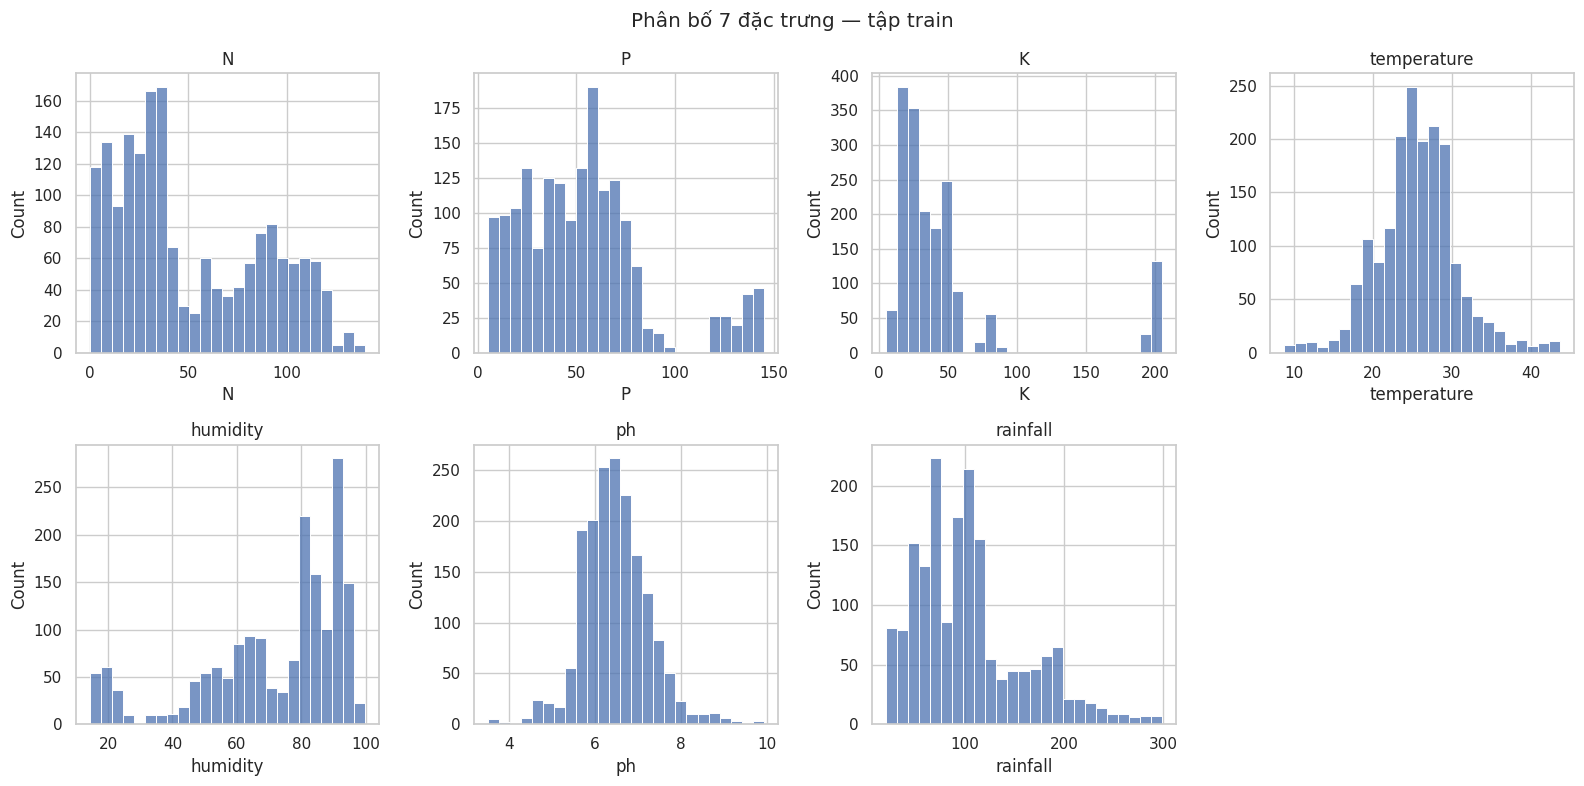

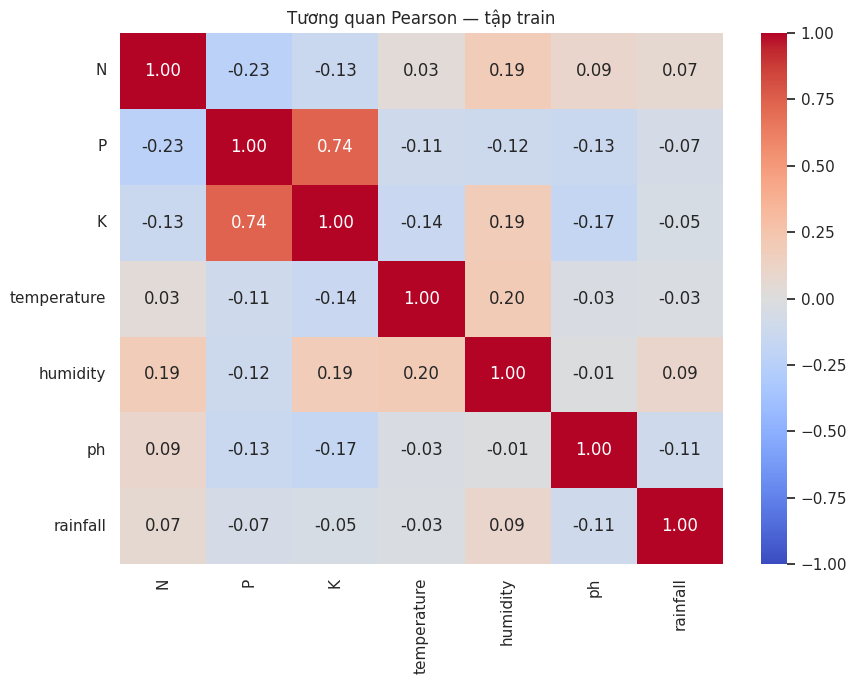

In [7]:
display(X_train.describe().T)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, feature in zip(axes.flat, FEATURES):
    sns.histplot(data=X_train, x=feature, bins=25, ax=ax)
    ax.set_title(feature)
axes.flat[-1].axis('off')
fig.suptitle('Phân bố 7 đặc trưng — tập train')
fig.tight_layout()
fig.savefig(OUT / 'feature_histograms.png', dpi=150)
plt.show()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(X_train.corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
ax.set_title('Tương quan Pearson — tập train')
fig.tight_layout()
fig.savefig(OUT / 'feature_correlation.png', dpi=150)
plt.show()

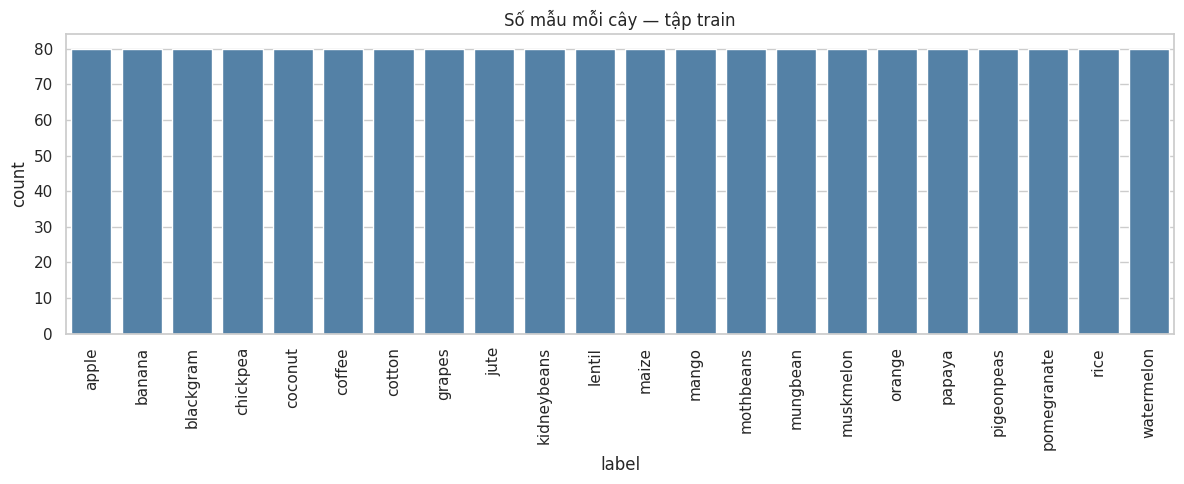

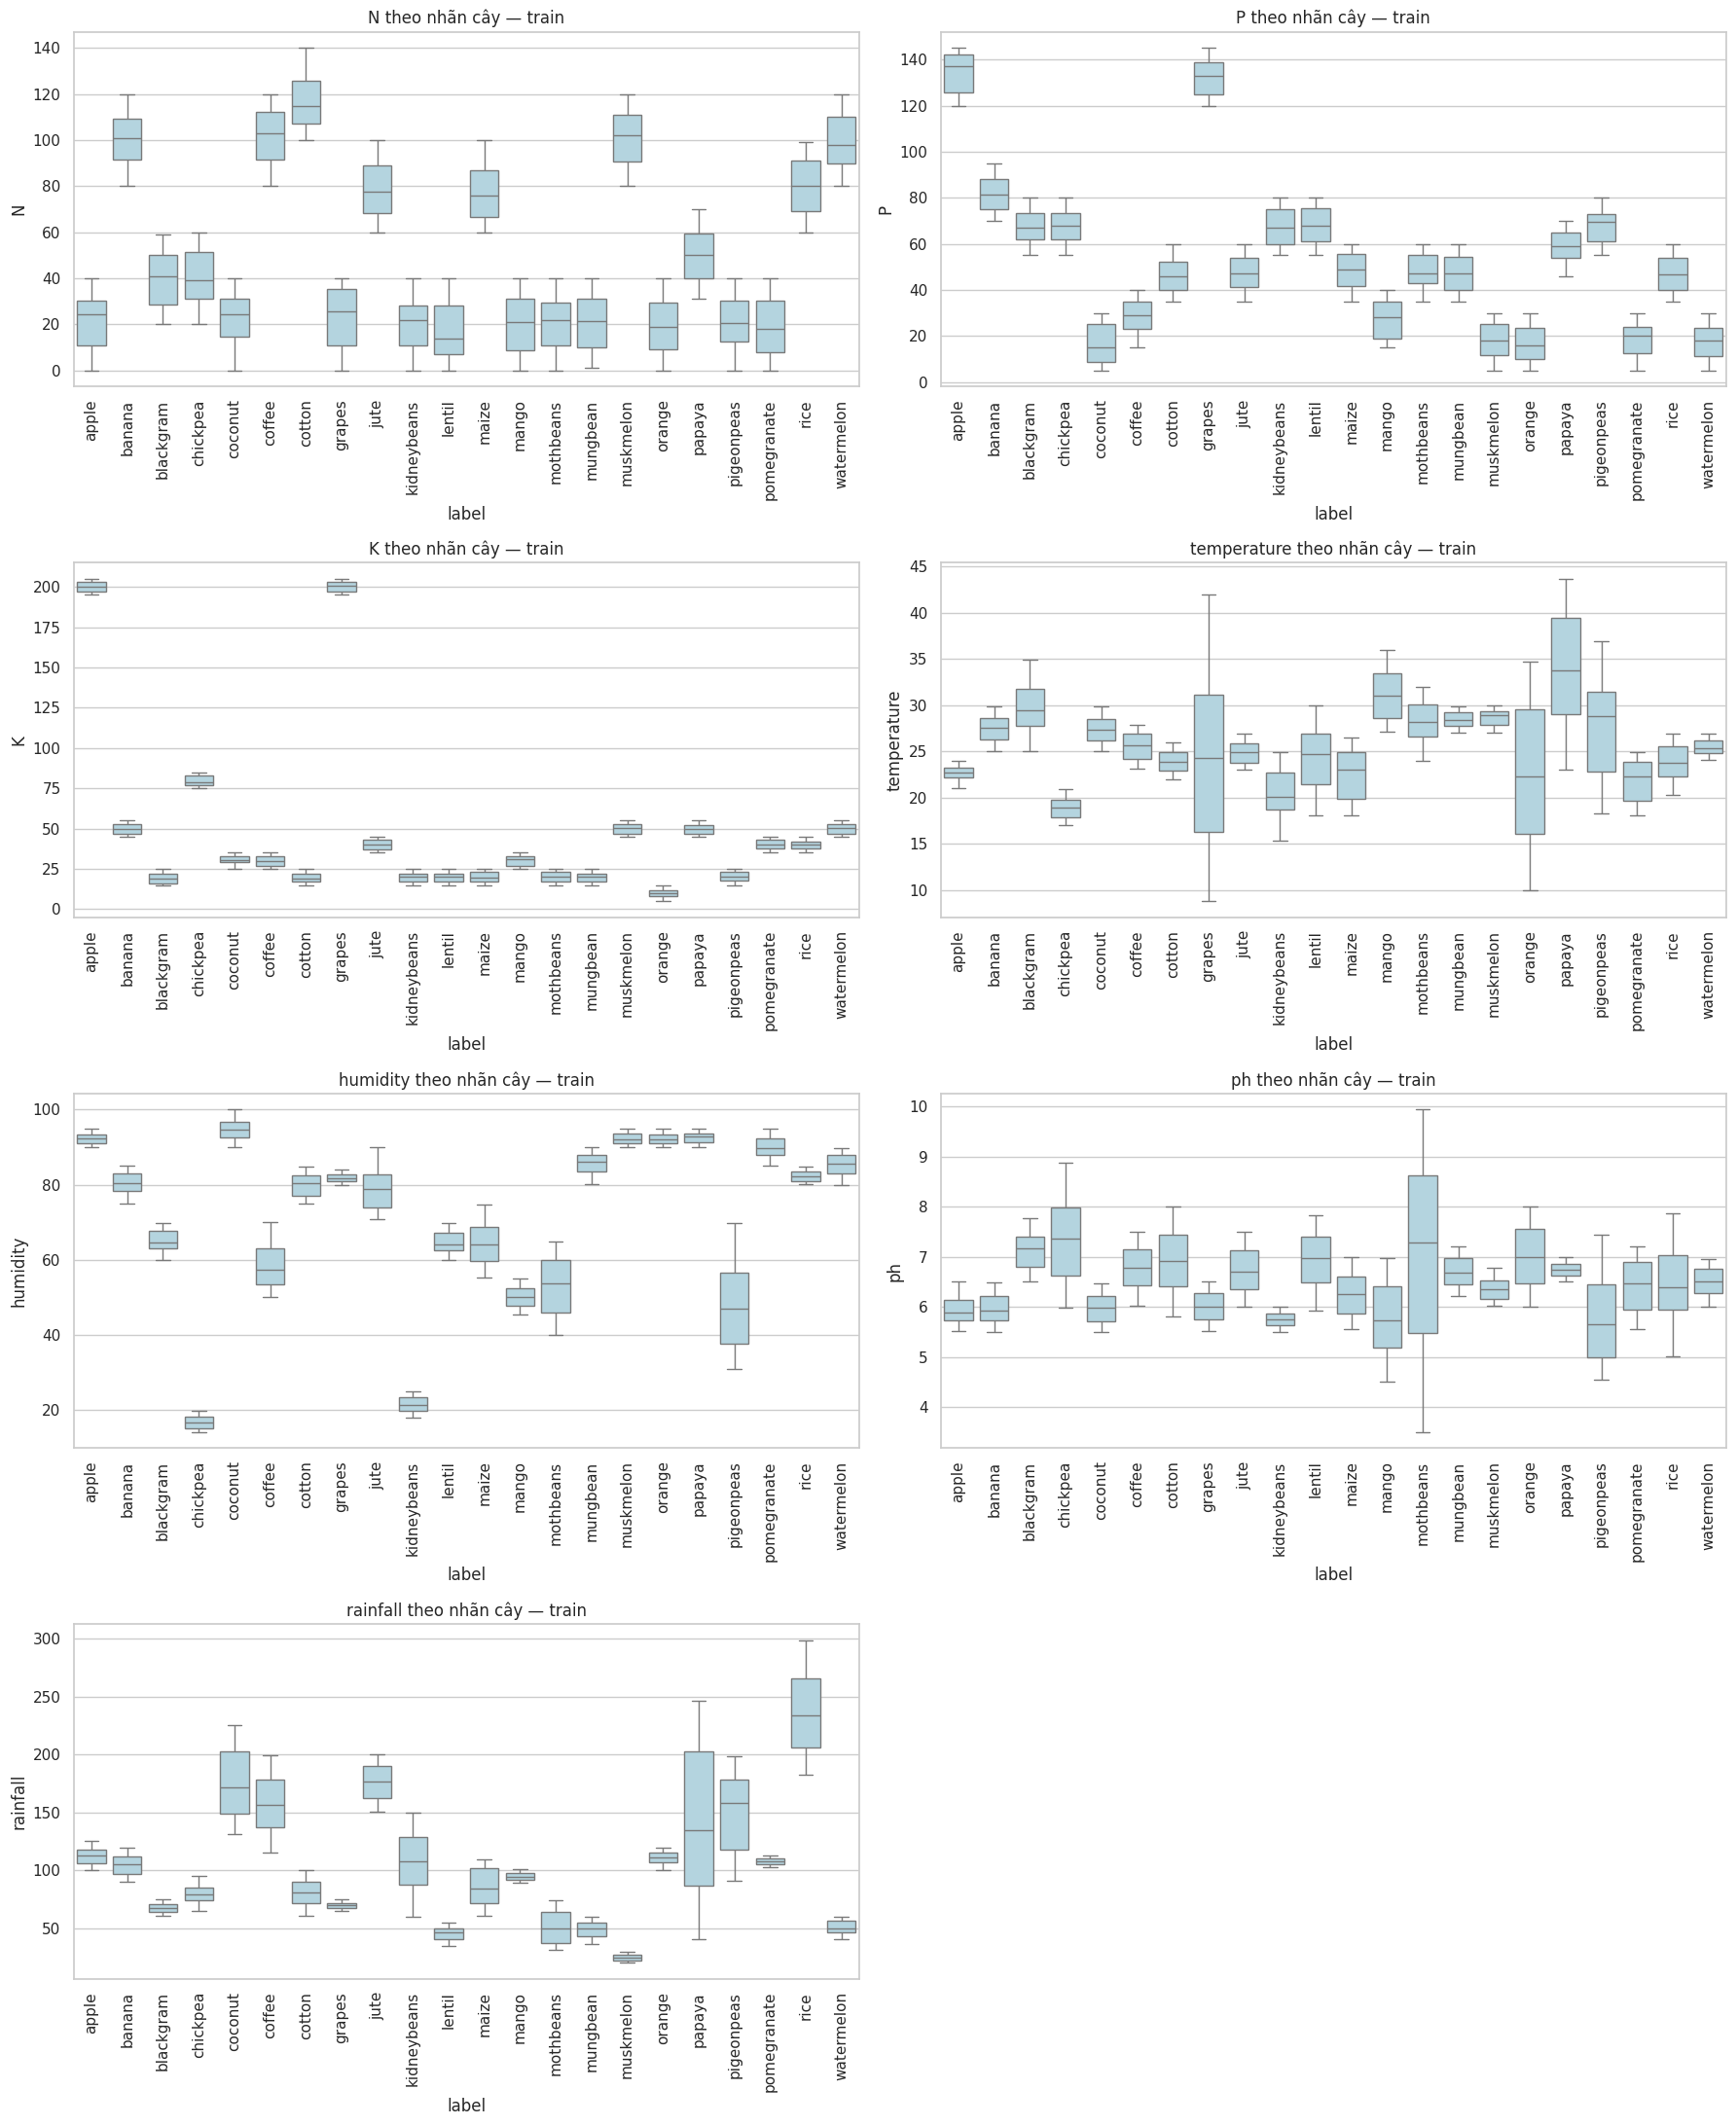

In [8]:
train_frame = X_train.join(y_train)
fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=train_frame, x='label', order=classes, color='steelblue', ax=ax)
ax.tick_params(axis='x', rotation=90)
ax.set_title('Số mẫu mỗi cây — tập train')
fig.tight_layout()
fig.savefig(OUT / 'class_distribution.png', dpi=150)
plt.show()
fig, axes = plt.subplots(4, 2, figsize=(18, 22))
for ax, feature in zip(axes.flat, FEATURES):
    sns.boxplot(data=train_frame, x='label', y=feature, order=classes, color='lightblue', ax=ax)
    ax.tick_params(axis='x', rotation=90)
    ax.set_title(f'{feature} theo nhãn cây — train')
axes.flat[-1].axis('off')
fig.tight_layout()
fig.savefig(OUT / 'features_by_crop.png', dpi=150)
plt.show()

### Nhận xét EDA trên tập train của lần chạy hiện tại

**Phân bố nhãn.** Dữ liệu có 22 lớp, mỗi lớp 100 mẫu. Sau chia phân tầng, train có 1.760 mẫu (80 mẫu/lớp), test có 440 mẫu (20 mẫu/lớp). Biểu đồ nhãn trên train cho thấy các lớp cân bằng về số lượng, nên chưa cần tăng hoặc giảm mẫu để cân bằng lớp.

**Thang đo và phân bố các đặc trưng.** K có trung vị 32, lớn nhất 205; rainfall có trung vị 94,773 và lớn nhất 298,560. Trong khi đó, ph có trung vị 6,431 và khoảng biến thiên nhỏ hơn nhiều. Các biến chênh lệch thang đo, nên cần khảo sát chuẩn hóa khi dùng khoảng cách. Biểu đồ N và P có nhiều vùng tập trung; K có một nhóm giá trị cao tách khỏi phần lớn mẫu ở mức thấp. Nhiệt độ tập trung quanh vùng giữa và có ít mẫu ở hai đầu.

Độ ẩm có trung bình 71,417% và trung vị 80,542%; nhiều mẫu nằm ở vùng độ ẩm cao, bên cạnh các nhóm thấp hơn. pH tập trung chủ yếu quanh 6–7. Lượng mưa có đuôi lệch phải, khiến trung bình lớn hơn trung vị. Vì hình dạng phân bố khác nhau, cần kiểm tra riêng từng biến trước khi chọn cách xử lý.

**Quan hệ giữa các đặc trưng và với nhãn.**

1. P và K có tương quan Pearson khoảng 0,736 (hiển thị 0,74 trên hình). Hai cột có thể chứa một phần thông tin giống nhau. Hiện vẫn giữ cả hai; việc bỏ cột cần được đánh giá ở giai đoạn mô hình.
2. Rainfall có tương quan tuyến tính yếu với các đầu vào còn lại. Điều này gợi ý lượng mưa có thể mang thông tin khác; chưa thể kết luận mức hữu ích cho phân loại chỉ từ ma trận tương quan.
3. Apple và grapes có K tập trung ở mức cao hơn nhiều lớp khác. Các điểm K cao có thể phản ánh đặc điểm của nhóm cây, nên không loại chỉ vì bị đánh dấu bởi IQR toàn cục.
4. Phân bố K của maize và rice chồng lấn, cùng có nhiều giá trị quanh mức 20. Vì vậy, một mình K khó phân biệt hai lớp; cần xem kết hợp với các đặc trưng còn lại.

Các nhận xét trên mô tả dữ liệu train, chưa phải kết quả đánh giá mô hình. Bộ dữ liệu chưa có mã thửa ruộng, địa điểm hoặc thời gian đo nên chưa kiểm tra được mức độ độc lập theo những nhóm này. Hiện mới dùng một nguồn dữ liệu; yêu cầu bổ sung nguồn thứ hai và gộp dữ liệu chưa được thực hiện.


### Bổ sung cho Bài kiểm tra 1 — thống kê chất lượng dữ liệu

Bạn tự chạy ô này sau mục 2–5. Ô chỉ thống kê, không fit mô hình, không thay đổi dữ liệu hoặc các kết quả đã có.
IQR được tính trên X_train. Một điểm ngoài hàng rào thống kê không mặc nhiên là dữ liệu sai; xem theo nhãn trước khi quyết định xử lý.
Số dòng có ít nhất một cờ khác tổng số cờ theo cột vì một dòng có thể bị đánh dấu nhiều lần.
Đối chiếu bảng với mục 2.7–2.8 của Bao_cao_Hoc_may.docx. Với đúng dữ liệu và split lần đầu, dự kiến có 349 dòng train được đánh dấu ít nhất một cột; đây là số liệu mô tả, không phải điểm đánh giá mô hình.


In [9]:
# Không huấn luyện; chỉ dùng các biến từ phần chuẩn bị dữ liệu.
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
iqr_flags = (X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)
quality_table = pd.DataFrame({
    'thieu_train': X_train.isna().sum(),
    'so_mau_ngoai_hang_rao_IQR': iqr_flags.sum(),
    'ty_le_%': iqr_flags.mean() * 100,
    'nguong_duoi': q1 - 1.5 * iqr,
    'nguong_tren': q3 + 1.5 * iqr,
})
display(quality_table)
print('Số dòng train có ít nhất một cờ:', int(iqr_flags.any(axis=1).sum()))
print('Số ô thiếu toàn bộ CSV:', int(raw.isna().sum().sum()))
print('Số dòng trùng toàn bộ CSV:', int(raw.duplicated(subset=FEATURES + ['label']).sum()))
display(pd.DataFrame({
    'chi_tieu': ['So mau', 'So dac trung', 'So nhan'],
    'truoc_kiem_tra': [len(raw), len(FEATURES), raw['label'].nunique()],
    'sau_kiem_tra': [len(df), len(FEATURES), df['label'].nunique()],
}))
print('Không xóa tự động các điểm IQR. Hãy giải thích quyết định giữ lại theo phân bố từng lớp.')


,thieu_train,so_mau_ngoai_hang_rao_IQR,ty_le_%,nguong_duoi,nguong_tren
N,0,0,0.000000,-75.000000,181.000000
P,0,108,6.136364,-32.000000,128.000000
K,0,160,9.090909,-23.500000,92.500000
temperature,0,72,4.090909,14.129748,37.202971
humidity,0,24,1.363636,15.626020,134.477785
ph,0,43,2.443182,4.492216,8.395438
rainfall,0,82,4.659091,-24.008797,212.152490


Số dòng train có ít nhất một cờ: 349
Số ô thiếu toàn bộ CSV: 0
Số dòng trùng toàn bộ CSV: 0


,chi_tieu,truoc_kiem_tra,sau_kiem_tra
0,So mau,2200,2200
1,So dac trung,7,7
2,So nhan,22,22


Không xóa tự động các điểm IQR. Hãy giải thích quyết định giữ lại theo phân bố từng lớp.


### Nhận xét chất lượng dữ liệu và quyết định xử lý

Kết quả kiểm tra ghi nhận **0 ô thiếu, 0 dòng trùng hoàn toàn, 0 nhóm có cùng đặc trưng nhưng khác nhãn và 0 trường hợp sai định dạng/miền giá trị đã kiểm tra**. Vì vậy, không điền khuyết và không loại thêm dòng nào. Nhãn giữ dạng chuỗi; các thư viện phân loại được chuẩn bị trong notebook hỗ trợ dạng này.

Trên 1.760 mẫu train, số điểm ngoài ngưỡng 1,5 IQR theo từng cột là: N **0**, P **108**, K **160**, temperature **72**, humidity **24**, ph **43**, rainfall **82**. Có **349 mẫu phân biệt**, tương đương **19,83% train**, bị đánh dấu ở ít nhất một cột. Một mẫu có thể được đếm ở nhiều cột. Đây là dấu hiệu cần xem xét, không phải số mẫu sai được xác nhận. Các mẫu được giữ lại vì phân bố theo nhãn cho thấy giá trị khác biệt có thể gắn với từng nhóm cây.

Trước và sau kiểm tra, dữ liệu vẫn có **2.200 mẫu, 7 đặc trưng và 22 nhãn**. Không cần tái lấy mẫu để cân bằng vì mỗi lớp có đúng 100 mẫu. Những kiểm tra đã thực hiện chưa xác nhận được độ chính xác của phép đo hoặc phát hiện mọi mẫu gần trùng.

Test được giữ riêng; EDA và ngưỡng IQR chỉ dùng train. Mã cho giai đoạn sau đặt scaler trong Pipeline để fit riêng trên train của từng fold, rồi áp dụng cho validation/test. Các ô chuẩn hóa và mô hình đó chưa chạy ở mốc hiện tại. Không có kết quả huấn luyện được suy ra từ các bảng thống kê trên.


---
## Điểm dừng của Bài kiểm tra 1 — phần mô hình bắt đầu bên dưới

**Bài kiểm tra 1:** thực hiện phần chuẩn bị, dữ liệu, chia tập và EDA ở mục 2–5, cùng ô thống kê chất lượng dữ liệu ngay phía trên. Dừng ở đây khi chỉ chuẩn bị cho mốc này.

**Các mô hình trong notebook:** mục 6 là KNN minh họa (`smoke_model`); mục 7 là KNN chính (`base_knn`); mục 9 là Gaussian Naive Bayes, Decision Tree và Random Forest để so sánh.

**Khai báo khác với huấn luyện:** `KNeighborsClassifier(...)` tạo đối tượng mô hình; `.fit(...)` học từ dữ liệu. Ở mục 7, ô khai báo `base_knn` và hàm `run_search` chưa huấn luyện; ô tiếp theo gọi `run_search('KNN', ...)` mới bắt đầu huấn luyện và tìm tham số.


## 6. MÔ HÌNH MINH HỌA — KNN nhỏ, có huấn luyện
**Ô này có `.fit()`**, chỉ dùng phần train của fold đầu tiên; không chạy GridSearch và không đụng test.
Dùng StandardScaler + Euclidean + K=5 + uniform. Xem 5 láng giềng của một mẫu validation và tự đếm phiếu.
Kết quả kỳ vọng về cấu trúc: bảng có 5 dòng láng giềng, xác suất 22 lớp, tổng xác suất bằng 1.
Không có ngưỡng Accuracy phải đạt; đây là bước kiểm tra cách hoạt động, không phải kết quả cuối.

In [ ]:
fit_pos, val_pos = cv_splits[0]
# MÔ HÌNH MINH HỌA: StandardScaler + KNN (5 láng giềng).
smoke_model = Pipeline([
    ('scale', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5, metric='euclidean', weights='uniform', algorithm='brute'))
])
# HUẤN LUYỆN mô hình minh họa bắt đầu tại lệnh này.
smoke_model.fit(X_train.iloc[fit_pos], y_train.iloc[fit_pos])
query = X_train.iloc[val_pos[:1]]
query_scaled = smoke_model.named_steps['scale'].transform(query)
distances, local_indices = smoke_model.named_steps['knn'].kneighbors(query_scaled)
neighbor_labels = y_train.iloc[fit_pos].iloc[local_indices[0]].to_numpy()
neighbor_table = X_train.iloc[fit_pos].iloc[local_indices[0]].copy()
neighbor_table['label'] = neighbor_labels
neighbor_table['distance_scaled'] = distances[0]
display(neighbor_table)
probability = smoke_model.predict_proba(query)[0]
manual_probability = np.array([(neighbor_labels == name).mean() for name in smoke_model.classes_])
np.testing.assert_allclose(probability, manual_probability)
assert probability.shape == (22,) and np.isclose(probability.sum(), 1)
print('Nhãn thật:', y_train.iloc[val_pos[0]], '| Dự đoán:', smoke_model.predict(query)[0])
display(pd.Series(probability, index=smoke_model.classes_, name='xac_suat').sort_values(ascending=False).head(5))
print('Đã đối chiếu predict_proba với phép đếm phiếu thủ công.')

## 7. MÔ HÌNH CHÍNH — KNN và tìm kiếm tham số
Lưới: 9 giá trị K × 3 scaler × 3 khoảng cách × 2 cách bỏ phiếu = **162 cấu hình**, mỗi cấu hình 5 fold.
Tổng **810 lần fit CV**, rồi refit cấu hình tốt nhất trên toàn bộ train. Lưới không lặp Euclidean với Minkowski p=2.
Chọn theo **F1 macro**, đồng thời ghi Accuracy. Giữ `algorithm='brute'` để khảo sát tốc độ tìm kiếm riêng ở mục 10.

Ô đầu chỉ tạo lưới/hàm và in số lượt, **chưa fit**. Ô sau mới gọi tìm kiếm.
CV dùng để chọn cấu hình nên điểm CV tốt nhất có thể lạc quan; không gọi nó là đánh giá độc lập cuối cùng.

In [ ]:
# MÔ HÌNH CHÍNH: KNN trong Pipeline; ô này chỉ khai báo, chưa huấn luyện.
base_knn = Pipeline([
    ('scale', 'passthrough'),
    # KNeighborsClassifier là thuật toán KNN của dự án.
    ('knn', KNeighborsClassifier(algorithm='brute', n_jobs=1))
])
common_grid = {
    'scale': ['passthrough', StandardScaler(), MinMaxScaler()],
    'knn__n_neighbors': K_VALUES,
    'knn__weights': ['uniform', 'distance'],
}
knn_grid = [
    {**common_grid, 'knn__metric': ['euclidean', 'manhattan']},
    {**common_grid, 'knn__metric': ['minkowski'], 'knn__p': [3]},
]
searches = {}

def run_search(name, estimator, grid):
    if (OUT / 'comparison.csv').exists():
        raise RuntimeError('Đã mở test ở lần chạy này. Không tiếp tục chỉnh tham số dựa vào test.')
    candidates = len(ParameterGrid(grid))
    print(f'{name}: {candidates} cấu hình × {N_SPLITS} fold = {candidates * N_SPLITS} lần fit CV, thêm 1 refit.')
    search = GridSearchCV(
        estimator, grid, scoring=SCORING, refit='f1_macro', cv=cv_splits,
        n_jobs=N_JOBS, return_train_score=True, error_score='raise', verbose=1,
    )
    with threadpool_limits(limits=1):
        # Lệnh huấn luyện này chỉ thực thi khi gọi hàm run_search.
        search.fit(X_train, y_train)
    joblib.dump(search, OUT / f'{name}_search.joblib')
    pd.DataFrame(search.cv_results_).to_csv(OUT / f'{name}_cv_raw.csv', index=False)
    searches[name] = search
    print('Tham số được chọn:', search.best_params_)
    print('CV F1 macro dùng chọn tham số:', search.best_score_)
    return search

print('Số cấu hình KNN:', len(ParameterGrid(knn_grid)))
print('Ô này chưa chạy tìm kiếm. Chạy ô tiếp theo khi bạn đã hiểu mục 6.')

In [ ]:
# HUẤN LUYỆN CHÍNH: chạy ô này sẽ tìm tham số KNN bằng kiểm định chéo.
# BẮT ĐẦU KHẢO SÁT KNN khi chính bạn chạy ô này.
knn_search = run_search('KNN', base_knn, knn_grid)

## 8. Đọc ảnh hưởng K, chuẩn hóa, khoảng cách và trọng số
Ô dưới chỉ xử lý kết quả đã chạy. Mỗi hàng có trung bình/độ lệch chuẩn 5 fold.
Các biểu đồ giữ các yếu tố khác ở giá trị đã chọn bởi CV, chỉ thay yếu tố đang khảo sát;
không lấy cực đại tùy ý trên mọi yếu tố rồi diễn giải thành ảnh hưởng riêng của một yếu tố.
Kết quả vẫn là phân tích trên dữ liệu dùng chọn mô hình.

In [ ]:
def scaler_name(value):
    if isinstance(value, str):
        return 'none'
    return 'standard' if isinstance(value, StandardScaler) else 'minmax'

cv_result = knn_search.cv_results_
rows = []
for i, params in enumerate(cv_result['params']):
    metric = params['knn__metric']
    rows.append({
        'K': params['knn__n_neighbors'], 'scaler': scaler_name(params['scale']),
        'distance': 'minkowski_p3' if metric == 'minkowski' else metric,
        'weights': params['knn__weights'],
        'cv_accuracy': cv_result['mean_test_accuracy'][i],
        'sd_accuracy': cv_result['std_test_accuracy'][i],
        'cv_f1_macro': cv_result['mean_test_f1_macro'][i],
        'sd_f1_macro': cv_result['std_test_f1_macro'][i],
        'train_f1_macro': cv_result['mean_train_f1_macro'][i],
    })
knn_results = pd.DataFrame(rows)
knn_results.to_csv(OUT / 'knn_cv.csv', index=False)
display(knn_results.sort_values('cv_f1_macro', ascending=False).head(10))
best_settings = knn_results.iloc[knn_search.best_index_][['K', 'scaler', 'distance', 'weights']].to_dict()
print('Giá trị cố định khi khảo sát từng yếu tố:', best_settings)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, factor in zip(axes.flat, ['K', 'scaler', 'distance', 'weights']):
    keep = pd.Series(True, index=knn_results.index)
    for other in ['K', 'scaler', 'distance', 'weights']:
        if other != factor:
            keep &= knn_results[other].eq(best_settings[other])
    part = knn_results.loc[keep].sort_values(factor)
    positions = np.arange(len(part))
    ax.errorbar(positions, part['cv_f1_macro'], yerr=part['sd_f1_macro'], marker='o', capsize=4, label='CV F1 macro ± SD')
    ax.plot(positions, part['cv_accuracy'], marker='s', label='CV Accuracy')
    ax.set_xticks(positions, part[factor].astype(str).tolist())
    ax.set_title(f'Thay đổi {factor}; các yếu tố khác cố định')
    ax.set_ylabel('Điểm')
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'knn_factors.png', dpi=150)
plt.show()

best_i = knn_search.best_index_
knn_folds = pd.DataFrame({
    'fold': range(1, N_SPLITS + 1),
    'accuracy': [cv_result[f'split{i}_test_accuracy'][best_i] for i in range(N_SPLITS)],
    'f1_macro': [cv_result[f'split{i}_test_f1_macro'][best_i] for i in range(N_SPLITS)],
})
knn_folds.to_csv(OUT / 'knn_selected_folds.csv', index=False)
display(knn_folds)

**Bạn tự nhận xét:** K nào tốt nhất? Không chuẩn hóa khác Standard/MinMax bao nhiêu?
Khoảng cách và weights có làm thay đổi kết quả đáng kể không? So sánh chênh lệch với SD giữa các fold.
Train F1 cao hơn CV F1 nhiều có thể gợi ý quá khớp; với K=1, điểm train rất cao là điều dễ xảy ra.
SD giữa các fold không phải khoảng tin cậy. Không có yêu cầu KNN phải thắng các mô hình khác.

## 9. CÁC MÔ HÌNH SO SÁNH — Gaussian Naive Bayes, Decision Tree, Random Forest
Chạy **từng ô**. Mỗi mô hình dùng cùng train, cùng 5 fold, cùng tiêu chí F1 macro; có lưới nhỏ để so sánh minh bạch.
Số cấu hình khác nhau, vì vậy hãy ghi rõ ngân sách khảo sát, không gọi đây là tìm kiếm tối ưu tuyệt đối cho mọi mô hình.
Gaussian NB giả định các đặc trưng độc lập có điều kiện theo lớp và phân bố Gaussian từng đặc trưng.
Decision Tree học các ngưỡng chia; Random Forest kết hợp nhiều cây huấn luyện với sự ngẫu nhiên.
Cây không cần chuẩn hóa cho phép chia theo ngưỡng; Gaussian NB dùng pipeline StandardScaler trong từng fold.

In [ ]:
# MÔ HÌNH SO SÁNH 1: Gaussian Naive Bayes; chạy ô này có huấn luyện.
# Thí nghiệm Gaussian NB: 3 cấu hình × 5 fold.
nb_search = run_search('GaussianNB', Pipeline([
    ('scale', StandardScaler()), ('model', GaussianNB())
]), {'model__var_smoothing': [1e-11, 1e-9, 1e-7]})

In [ ]:
# MÔ HÌNH SO SÁNH 2: Decision Tree; chạy ô này có huấn luyện.
# Thí nghiệm Decision Tree: 6 cấu hình × 5 fold.
tree_search = run_search('DecisionTree', DecisionTreeClassifier(random_state=SEED), {
    'max_depth': [None, 5, 10], 'min_samples_leaf': [1, 3]
})

In [ ]:
# MÔ HÌNH SO SÁNH 3: Random Forest; chạy ô này có huấn luyện.
# Thí nghiệm Random Forest: 4 cấu hình × 5 fold, mỗi rừng gồm 200 cây.
forest_search = run_search('RandomForest', RandomForestClassifier(
    n_estimators=200, random_state=SEED, n_jobs=1
), {'max_depth': [None, 10], 'min_samples_leaf': [1, 2]})

## 10. Brute, KD-Tree và Ball-Tree — bạn tự chạy benchmark
Giữ cố định scaler, K, metric, weights từ KNN đã chọn; so sánh `brute`, `kd_tree`, `ball_tree` trên fold đầu của train.
Đo thời gian fit cả pipeline và thời gian `kneighbors` cho cùng một batch validation đã biến đổi.
Lặp 5 lần, đổi thứ tự chạy và lấy trung vị; không chạy tác vụ nặng khác trên máy lúc đo.

`query_ms_per_sample` là thời gian batch chia số mẫu, không phải độ trễ của từng request riêng lẻ.
Bảng còn kiểm tra khoảng cách láng giềng và tỷ lệ nhãn trùng brute; đồng khoảng cách có thể làm khác nhãn.
Không khẳng định cấu trúc nào nhanh nhất trước khi đo. Demo vẫn giữ `brute` như trong khảo sát; benchmark không tự đổi mô hình.

In [ ]:
fit_pos, val_pos = cv_splits[0]
X_fit, y_fit = X_train.iloc[fit_pos], y_train.iloc[fit_pos]
X_query = X_train.iloc[val_pos]
benchmark_rows = []
backend_predictions, backend_distances = {}, {}
rng = np.random.default_rng(SEED)
with threadpool_limits(limits=1):
    for repeat in range(5):
        for algorithm in rng.permutation(['brute', 'kd_tree', 'ball_tree']):
            candidate = clone(knn_search.best_estimator_).set_params(knn__algorithm=str(algorithm), knn__n_jobs=1)
            start = perf_counter()
            candidate.fit(X_fit, y_fit)
            fit_ms = (perf_counter() - start) * 1000
            scale = candidate.named_steps['scale']
            transformed = X_query if isinstance(scale, str) else scale.transform(X_query)
            neighbor_model = candidate.named_steps['knn']
            neighbor_model.kneighbors(transformed[:1])  # Warm-up không tính vào thời gian.
            start = perf_counter()
            distances, _ = neighbor_model.kneighbors(transformed)
            query_ms = (perf_counter() - start) * 1000
            backend_predictions[str(algorithm)] = candidate.predict(X_query)
            backend_distances[str(algorithm)] = distances
            benchmark_rows.append({
                'algorithm': str(algorithm), 'repeat': repeat + 1, 'n_query': len(X_query),
                'fit_ms': fit_ms, 'query_batch_ms': query_ms,
                'query_ms_per_sample': query_ms / len(X_query),
            })
benchmark = pd.DataFrame(benchmark_rows)
benchmark.to_csv(OUT / 'neighbors_benchmark_raw.csv', index=False)
benchmark_summary = benchmark.groupby('algorithm')[['fit_ms', 'query_batch_ms', 'query_ms_per_sample']].median()
benchmark_summary['label_agreement_with_brute'] = [
    np.mean(backend_predictions[algorithm] == backend_predictions['brute'])
    for algorithm in benchmark_summary.index
]
benchmark_summary['distances_equal_to_brute'] = [
    np.allclose(backend_distances[algorithm], backend_distances['brute'], rtol=1e-6, atol=1e-8)
    for algorithm in benchmark_summary.index
]
benchmark_summary.to_csv(OUT / 'neighbors_benchmark.csv')
display(benchmark_summary)
print('Benchmark trên train/CV; chưa dùng holdout test.')

## 11. Chốt mô hình bằng CV, rồi mở test một lần
Accuracy là tỷ lệ đoán đúng. F1 macro là trung bình F1 của 22 lớp, mỗi lớp có trọng số ngang nhau.
Ô đầu chốt lựa chọn **trước khi tính điểm test**; ô thứ hai đánh giá bốn mô hình đã chốt.
Demo dùng KNN vì trọng tâm đề tài; bảng vẫn ghi trung thực nếu mô hình khác tốt hơn.

Không điều chỉnh tham số sau khi xem test để cải thiện bảng. Điểm CV dùng để chọn cấu hình là điểm phục vụ lựa chọn;
điểm test là đánh giá holdout. Nếu cần đánh giá toàn bộ quy trình tuning bằng CV độc lập thì mở rộng nested CV,
không lấy lại CV của cấu hình tốt nhất rồi gọi đó là nested CV.

In [ ]:
required_models = ['KNN', 'GaussianNB', 'DecisionTree', 'RandomForest']
assert set(searches) == set(required_models), 'Cần hoàn thành mục 7 và cả 3 ô ở mục 9.'
cv_rows = []
for name in required_models:
    search = searches[name]
    i = search.best_index_
    result = search.cv_results_
    cv_rows.append({
        'model': name,
        'cv_accuracy': result['mean_test_accuracy'][i], 'cv_accuracy_sd': result['std_test_accuracy'][i],
        'cv_f1_macro': result['mean_test_f1_macro'][i], 'cv_f1_macro_sd': result['std_test_f1_macro'][i],
        'candidates': len(result['params']), 'best_params': str(search.best_params_),
    })
cv_summary = pd.DataFrame(cv_rows)
cv_summary.to_csv(OUT / 'cv_summary.csv', index=False)
selected_name = cv_summary.sort_values('cv_f1_macro', ascending=False, kind='stable').iloc[0]['model']
selection = {
    'best_family_by_cv': selected_name, 'demo_model': 'KNN', 'selection_metric': 'f1_macro',
    'selected_knn': {key: str(value) for key, value in knn_search.best_params_.items()},
    'note': 'Đã chọn trên train/CV, trước khi mở test. KNN là mô hình minh họa của đề tài.',
}
(OUT / 'selection.json').write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
display(cv_summary)
print('Mô hình có CV F1 macro cao nhất:', selected_name)

In [ ]:
# ĐÁNH GIÁ TEST: chỉ chạy sau khi bạn đã chốt thí nghiệm.
if (OUT / 'comparison.csv').exists():
    raise RuntimeError('Test đã được đánh giá. Mở comparison.csv để xem lại, không tuning tiếp từ test.')
test_rows = []
test_predictions = {}
for name in required_models:
    estimator = searches[name].best_estimator_  # Đã refit trên train, không fit thêm ở đây.
    predicted = estimator.predict(X_test)
    test_predictions[name] = predicted
    test_rows.append({
        'model': name, 'test_accuracy': accuracy_score(y_test, predicted),
        'test_f1_macro': f1_score(y_test, predicted, labels=classes, average='macro', zero_division=0),
    })
    report = classification_report(y_test, predicted, labels=classes, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(OUT / f'{name}_classification_report.csv')
    fig, ax = plt.subplots(figsize=(13, 12))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=classes, display_labels=classes,
        xticks_rotation=90, cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set_title(f'{name}: ma trận nhầm lẫn test (số mẫu)')
    ax.set_xlabel('Nhãn dự đoán')
    ax.set_ylabel('Nhãn thật')
    fig.tight_layout()
    fig.savefig(OUT / f'{name}_confusion_matrix.png', dpi=150)
    plt.show()
comparison = cv_summary.merge(pd.DataFrame(test_rows), on='model')
comparison.to_csv(OUT / 'comparison.csv', index=False)
predictions_table = X_test.copy()
predictions_table['true_label'] = y_test
for name, predicted in test_predictions.items():
    predictions_table[f'pred_{name}'] = predicted
predictions_table.to_csv(OUT / 'test_predictions.csv')
display(comparison.drop(columns='best_params'))
knn_errors = predictions_table.loc[predictions_table['true_label'] != predictions_table['pred_KNN']]
knn_errors.to_csv(OUT / 'knn_errors.csv')
print('Số mẫu KNN dự đoán sai:', len(knn_errors))
display(knn_errors.head(10))

## 12. Lưu pipeline KNN để dùng lại — không huấn luyện thêm
Lưu cả scaler và KNN để demo tự dùng đúng tiền xử lý. Giữ mô hình đã fit trên train, không refit bằng test.
File lưu kèm thứ tự cột, nhãn, min/max train, phiên bản và dấu vân tay dữ liệu.
Tạo file `joblib` không phải xuất ONNX; môn Học máy này dùng scikit-learn trực tiếp để giữ bài đơn giản.

In [ ]:
assert (OUT / 'comparison.csv').exists(), 'Hãy đánh giá ở mục 11 trước khi lưu bản demo.'
bundle = {
    'schema_version': 1,
    'pipeline': knn_search.best_estimator_,
    'features': FEATURES,
    'classes': knn_search.best_estimator_.classes_.tolist(),
    'training_bounds': {name: [float(X_train[name].min()), float(X_train[name].max())] for name in FEATURES},
    'versions': VERSIONS, 'data_sha256': data_sha256,
    'selection': selection, 'train_source_rows': train_ids.tolist(),
}
MODEL_PATH = OUT / 'knn_crop.joblib'
joblib.dump(bundle, MODEL_PATH)
metadata = {key: value for key, value in bundle.items() if key != 'pipeline'}
(OUT / 'model_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu:', MODEL_PATH)
print('Chưa kiểm tra lưu/nạp. Bạn tự chạy mục 13 để đối chiếu.')

## 13. Bạn tự kiểm thử lưu/nạp và kiểm tra đầu vào
Ô này không train. Nó so sánh xác suất trước/sau khi nạp file trên 8 mẫu train, kiểm tra tổng xác suất,
đảm bảo đầu vào đảo thứ tự trường vẫn được sắp đúng, và kiểm tra lỗi mẫu thiếu trường/pH ngoài miền/NaN.
Nếu có assertion lỗi, dừng tại đó và đọc thông báo; không ghi là kiểm thử đạt.
Đây là kiểm tra chương trình, không thay thế Accuracy/F1 ở mục 11.

In [ ]:
loaded_bundle = load_bundle(MODEL_PATH)
probe = X_train.iloc[:8]
original_prob = bundle['pipeline'].predict_proba(probe)
loaded_prob = loaded_bundle['pipeline'].predict_proba(probe)
np.testing.assert_allclose(original_prob, loaded_prob, rtol=1e-12, atol=1e-12)
assert loaded_prob.shape == (len(probe), 22)
np.testing.assert_allclose(loaded_prob.sum(axis=1), np.ones(len(probe)))
sample_check = X_train.iloc[0].to_dict()
top3_check, _ = recommend_top3(loaded_bundle, dict(reversed(list(sample_check.items()))))
assert len(top3_check) == 3 and top3_check['xac_suat'].is_monotonic_decreasing
assert top3_check['xac_suat'].sum() <= 1 + 1e-12
bad_samples = [
    {name: value for name, value in sample_check.items() if name != 'N'},
    {**sample_check, 'ph': 20},
    {**sample_check, 'temperature': float('nan')},
]
for bad_sample in bad_samples:
    try:
        validate_sample(bad_sample)
    except ValueError:
        pass
    else:
        raise AssertionError('Đầu vào sai chưa được chặn.')
print('ĐẠT: lưu/nạp giữ nguyên xác suất; top-3 hợp lệ; các đầu vào sai thử nghiệm được chặn.')

In [ ]:
from pathlib import Path
from google.colab import files
import shutil
import sys
import json
from importlib.metadata import version

run_dir = Path('/content/outputs/lan_01')  # Sửa nếu bạn đổi RUN_NAME.
if not (run_dir / 'knn_crop.joblib').is_file():
    raise FileNotFoundError('Chưa có mô hình; hoàn thành mục 12–13 trước.')

# Lưu phiên bản thực tế để đối chiếu khi dùng trên máy cá nhân.
packages = ['numpy', 'scipy', 'pandas', 'scikit-learn', 'joblib', 'threadpoolctl']
(run_dir / 'inference-requirements.txt').write_text(
    '\n'.join(f'{name}=={version(name)}' for name in packages) + '\n', encoding='utf-8'
)
(run_dir / 'python_runtime.json').write_text(
    json.dumps({'python': sys.version}, indent=2), encoding='utf-8'
)
archive = shutil.make_archive(
    '/content/crop_ml_results', 'zip',
    root_dir='/content', base_dir=f'outputs/{run_dir.name}',
)
files.download(archive)

## 14. Demo top-3 với một mẫu mới — chỉ dự đoán
Sửa 7 giá trị trong `new_soil` rồi chạy ô. Các số bên dưới chỉ là **ví dụ giả định**, không phải số đo đã kiểm chứng.
Tên cây giữ nguyên nhãn nguồn để tránh dịch sai các loại đậu. Không cần train lại khi nhập một mẫu khác.

Ô này dùng được sau Restart Kernel nếu bạn đặt thư mục làm việc ở gốc dự án và đã có file ở mục 12.
N/P/K phải cùng thang đo nguồn; humidity là độ ẩm tương đối, không tự thay bằng độ ẩm đất.
Rainfall phải dùng cùng kỳ tích lũy nguồn; nếu chưa rõ thì chỉ dùng minh họa bằng dữ liệu của bộ này.

KNN có thể chỉ bỏ phiếu cho 1–2 lớp. Bảng vẫn hiện 3 dòng nhưng đánh dấu các dòng 0% là không đủ căn cứ.
Không chia lại xác suất top-3 thành tổng 100%; phần xác suất còn lại thuộc 19 lớp khác.
100% phiếu không đồng nghĩa chắc chắn đúng hoặc cây sẽ trồng thành công. Các điểm này chưa được hiệu chỉnh xác suất.

In [ ]:
from pathlib import Path
from IPython.display import display
from demo import load_bundle, recommend_top3

# Đổi lan_01 nếu bạn lưu kết quả ở RUN_NAME khác.
demo_bundle = load_bundle(Path('outputs/lan_01/knn_crop.joblib'))
new_soil = {
    'N': 85, 'P': 40, 'K': 40,
    'temperature': 26.0, 'humidity': 80.0, 'ph': 6.5, 'rainfall': 200.0,
}
top3, notes = recommend_top3(demo_bundle, new_soil)
display(top3)
for note in notes:
    print('-', note)

## 15. Tự hoàn thiện bài nộp
Điền `BAO_CAO_GOI_Y.md` bằng kết quả thật của bạn. Lưu notebook sau khi chạy để giữ hình và bảng.
Ghi nhận xét về scaling, K/metric/weights, tốc độ tìm láng giềng, lớp dễ nhầm và giới hạn dữ liệu.
Bài toán gốc chỉ có một nhãn cho mỗi mẫu, không có đánh giá độc lập về nhiều cây cùng phù hợp trên một thửa ruộng.
Vì vậy top-3 là xếp hạng nhãn của mô hình; chưa xác nhận ba phương án nông nghiệp ngoài thực tế.

Nguồn tham khảo:

- [Crop Recommendation Dataset — Kaggle](https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset).
- [KNN, khoảng cách, KD-Tree/Ball-Tree](https://scikit-learn.org/1.7/modules/neighbors.html).
- [GridSearchCV](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [StratifiedKFold](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.StratifiedKFold.html).
- [Rò rỉ dữ liệu và Pipeline](https://scikit-learn.org/1.7/common_pitfalls.html).
- [Nested và non-nested CV](https://scikit-learn.org/1.7/auto_examples/model_selection/plot_nested_cross_validation_iris.html).
- [Gaussian Naive Bayes](https://scikit-learn.org/1.7/modules/naive_bayes.html).
- [Decision Trees](https://scikit-learn.org/1.7/modules/tree.html).
- [Random Forest](https://scikit-learn.org/1.7/modules/ensemble.html#forest).

Mã được chuẩn bị với trợ lý AI. Bạn chịu trách nhiệm kiểm tra, thực hiện thí nghiệm và giải thích kết quả theo quy định môn học.